#LangGraph - Workflow with LLMs



##Setup

In [1]:
!pip install langgraph langchain_core langchain_groq

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2/2 [langchain_groq]


In [2]:
!pip install grandalf

In [3]:
# Set Groq API token
# In Prod should be done through .env files
import os
os.environ['GROQ_API_KEY'] = "<YOUR API KEY HERE>"

##Example 2 - Build out first Workflow with LLMs (Model Router)

07-model-router-2.svg

In [70]:
# Define models
SMALL_MODEL = "openai/gpt-oss-20b"
BIG_MODEL = "openai/gpt-oss-120b"

In [69]:
# Build the custom State
from typing import TypedDict, Annotated
from langgraph.graph.message import add_messages

# Define State
class MyCustomState(TypedDict):
  route: str # EASY Or HARD
  messages: Annotated[list, add_messages]


In [89]:
# Define SYSTEM PROMPTS for all models

classify_model_sys_prompt = """You are a routing classifier who decides whether a user's question is easy or hard based on simple multistep reasoning.
Answer only in one word - EASY or HARD"""

small_model_sys_prompt = "Answer the user question."
big_model_sys_prompt = "Answer the user question elaborately."


In [90]:
# Define classifier model
from langchain_groq import ChatGroq

classify_model = ChatGroq(
    model = SMALL_MODEL,
    temperature = 0,
    max_tokens = 1000
)


In [91]:
# Test Classifier model

classify_model.invoke([{"role":"system", "content": classify_model_sys_prompt}, {"role":"user", "content":"What is 2+2?"}]).content

'EASY'

In [92]:
# Small Model
from langchain_groq import ChatGroq

_small_model = ChatGroq(
    model = SMALL_MODEL,
    temperature = 0,
    max_tokens = 1000
)



In [94]:
# Big Model

from langchain_groq import ChatGroq

_big_model = ChatGroq(
    model = BIG_MODEL,
    temperature = 0,
    max_tokens = 10000
)


In [95]:
# Define Classify Node
def classify(state: MyCustomState) -> dict:
  output = classify_model.invoke([{"role":"system", "content": classify_model_sys_prompt}] + state['messages']).content
  return {'route': output}



In [96]:
# Define the Small model node
def small_model(state: MyCustomState) -> dict:
  output = _small_model.invoke([{"role":"system", "content": small_model_sys_prompt}] + state['messages']).content
  return {'messages':[output]}


In [97]:
# Define the Big model node
def big_model(state: MyCustomState) -> dict:
  output = _big_model.invoke([{"role":"system", "content": big_model_sys_prompt}] + state['messages']).content
  return {'messages':[output]}


In [98]:
# Build the node
from langgraph.graph import StateGraph, START, END

builder = StateGraph(MyCustomState)
builder.add_node("classify", classify)
builder.add_node("small_model", small_model)
builder.add_node("big_model", big_model)



In [99]:
# Routing Edge
def router(state: MyCustomState) -> str:
  if state['route'] == 'EASY':
    return "small_model"
  else:
    return "big_model"


In [100]:
# Add Edges
builder.add_edge(START, "classify")
builder.add_conditional_edges("classify", router, ["small_model", "big_model"])
builder.add_edge("small_model", END)
builder.add_edge("big_model", END)


In [101]:
# Compile the graph
graph = builder.compile()


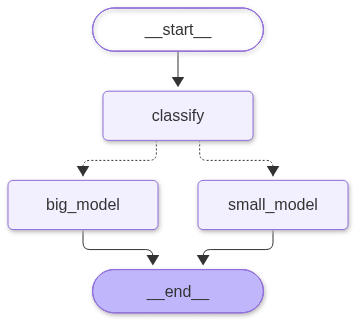

In [102]:
graph

In [103]:
# Run the Workflow using INVOKE
intial_state = {"messages": [{"role":"user", "content":"What is Qunatum Physics?"}], "route":""}

output = graph.invoke(intial_state)
print(output)


{'route': 'EASY', 'messages': [HumanMessage(content='What is Qunatum Physics?', additional_kwargs={}, response_metadata={}, id='bd92cfbf-1d40-46e3-878d-243c4072cdf1'), HumanMessage(content='**Quantum physics** (also called quantum mechanics or quantum theory) is the branch of physics that describes how the universe works at the smallest scales—atoms, electrons, photons, and other sub‑atomic particles. At these scales, the rules of everyday “classical” physics (Newton’s laws, Maxwell’s equations, etc.) no longer give accurate predictions, and a new set of principles takes over.\n\n---\n\n## Core Ideas\n\n| Concept | What It Means | Everyday Analogy (if any) |\n|---------|---------------|--------------------------|\n| **Quantization** | Energy, angular momentum, and other quantities come in discrete “chunks” (quanta) rather than a continuous range. | Like climbing a staircase: you can stand on the steps, not in between. |\n| **Wave‑Particle Duality** | Particles such as electrons and pho

In [106]:
# Run the Workflow using STREAM
for output in graph.stream(intial_state, stream_mode="values"):
  print(output)


{'route': '', 'messages': [HumanMessage(content='What is Qunatum Physics?', additional_kwargs={}, response_metadata={}, id='12bff3f5-1de0-46a5-a1d0-4341dca0ccf2')]}
{'route': 'EASY', 'messages': [HumanMessage(content='What is Qunatum Physics?', additional_kwargs={}, response_metadata={}, id='12bff3f5-1de0-46a5-a1d0-4341dca0ccf2')]}
{'route': 'EASY', 'messages': [HumanMessage(content='What is Qunatum Physics?', additional_kwargs={}, response_metadata={}, id='12bff3f5-1de0-46a5-a1d0-4341dca0ccf2'), HumanMessage(content='**Quantum physics** (also called quantum mechanics or quantum theory) is the branch of physics that describes how the universe works at the smallest scales—atoms, electrons, photons, and other sub‑atomic particles. At these scales, the rules of everyday “classical” physics (Newton’s laws, Maxwell’s equations, etc.) no longer give accurate predictions, and a new set of principles takes over.\n\n---\n\n## Core Ideas\n\n| Concept | What It Means | Everyday Analogy (if any) |